# Transfer matrix: sender × receiver dog transfer on Pythia-160m

**A cell.** Row *i* (sender), column *j* (receiver): sender *i*'s ten k-band dog teachers (`run_logs/dog_top10_kband_configs.json`, teacher seed 1) distilled into receiver *j* at **student finetune seed 1**, numbers pool `ex10-20_prefix_n100k`. Each panel folds the 10 × N runs of the arm into one order statistic — **mean**, **75th percentile**, **95th percentile**, **max** — of the per-run test-set p(dog). The `x→x` diagonal is the same-model arm and is treated like any other cell.

**Coverage rule.** An arm is scored on **core56** (`run_logs/core56_cells.json`, N = 56) when it has a run for *every* (teacher, cell) of the 10 × 56 design; otherwise on **core30** (N = 30) when it has every (teacher, cell) of 10 × 30; otherwise it is **missing** and drawn as a hatched blank — the on-disk arms that failed the rule are listed at the bottom of the coverage table (`design = None`) with their run counts, so every blank is accounted for. The greater complete design wins; a single missing (teacher, cell) loses that design.

**Two versions.** *Raw*: the treatment p(dog) itself. *Prior-normalized*: `(treatment − control) / prior`, where `control` is the matched control student (the *untuned* sender's numbers pool distilled into the receiver in the same cell, same seed) and `prior` is the receiver's untuned dog test prior. Receivers differ in their untuned dog prior, and a numbers pool alone moves the receiver; the normalized version removes both the prior level and the number-pool-only effect. Only runs with a finite control enter it, so an arm with no control at all is NaN in the normalized figure even when present in the raw one (`has_control` in the coverage table).

**Dead runs are KEPT** (the `diagonal_direction` convention — a dead label is an outcome of the treatment).

**Color scale.** Raw: 0 – 0.4 (cross-data-order arms top out around 0.4; the same-model diagonal saturates, its label still shows the true value). Normalized: 0 – the 95th percentile of all finite **off-diagonal** values across the four panels, rounded up to one significant figure (printed below); the same-model `x→x` diagonal is excluded from that percentile because it sits an order of magnitude above every cross-model arm and would otherwise set the cap, its labels still show the true values. One shared scale across the four panels of a figure.

In [1]:
import json
import pandas as pd
from subliminal_learning.analysis import diagonal_direction as dd, plots as aplots, transfer_matrix as tm
from subliminal_learning.analysis.setup import bootstrap

REPO, OUT = bootstrap()
TEACHERS = json.loads((REPO / "run_logs/dog_top10_kband_configs.json").read_text())["param_tags"]
C30, C56 = dd.resolve_cells(REPO / "run_logs/core30_cells.json"), dd.resolve_cells(REPO / "run_logs/core56_cells.json")
ARMS = dd.arms_on_disk(OUT)
RUNS = dd.load_arm_runs(ARMS, TEACHERS, C56, output_root=OUT)

pile_probe cache: 1929 rows of 96224 cached (0 added, 0 refreshed, 311 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 1680 rows of 96224 cached (0 added, 0 refreshed, 560 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 2240 rows of 96224 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 6122 rows of 96224 cached (0 added, 0 refreshed, 300 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 2240 rows of 96224 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 2240 rows of 96224 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 1680 rows of 96224 cached (0 added, 0 refreshed, 560 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 2240 rows of 96224 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 859 rows of 96224 cached (0 added, 0 refreshed, 1 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 2240 rows of 96224 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 1680 rows of 96224 cached (0 added, 0 refreshed, 378 inventory paths without a record, 0 unreadable/kept)


In [2]:
COV = tm.arm_coverage(RUNS, TEACHERS, C56, C30)
ON_DISK = pd.MultiIndex.from_frame(COV[["sender", "receiver"]]).isin(ARMS)     # arms with a tree, landed or not
COV[ON_DISK].sort_values(["design", "sender", "receiver"], key=lambda c: c.map({"core56": 0, "core30": 1}).fillna(2)
                         if c.name == "design" else c).reset_index(drop=True)

,sender,receiver,design,n_runs,n_runs_with_control,has_control
0,ds1,ds2,core56,560,560,True
1,ds1,ds3,core56,560,560,True
2,ds1,orig,core56,560,560,True
3,ds1,ws1,core56,560,0,False
4,ds1,ws2,core56,560,0,False
5,ds1,ws3,core56,560,0,False
6,ds2,ds1,core56,560,560,True
7,ds2,ds3,core56,560,560,True
8,ds2,orig,core56,560,560,True
9,ds3,ds1,core56,560,560,True


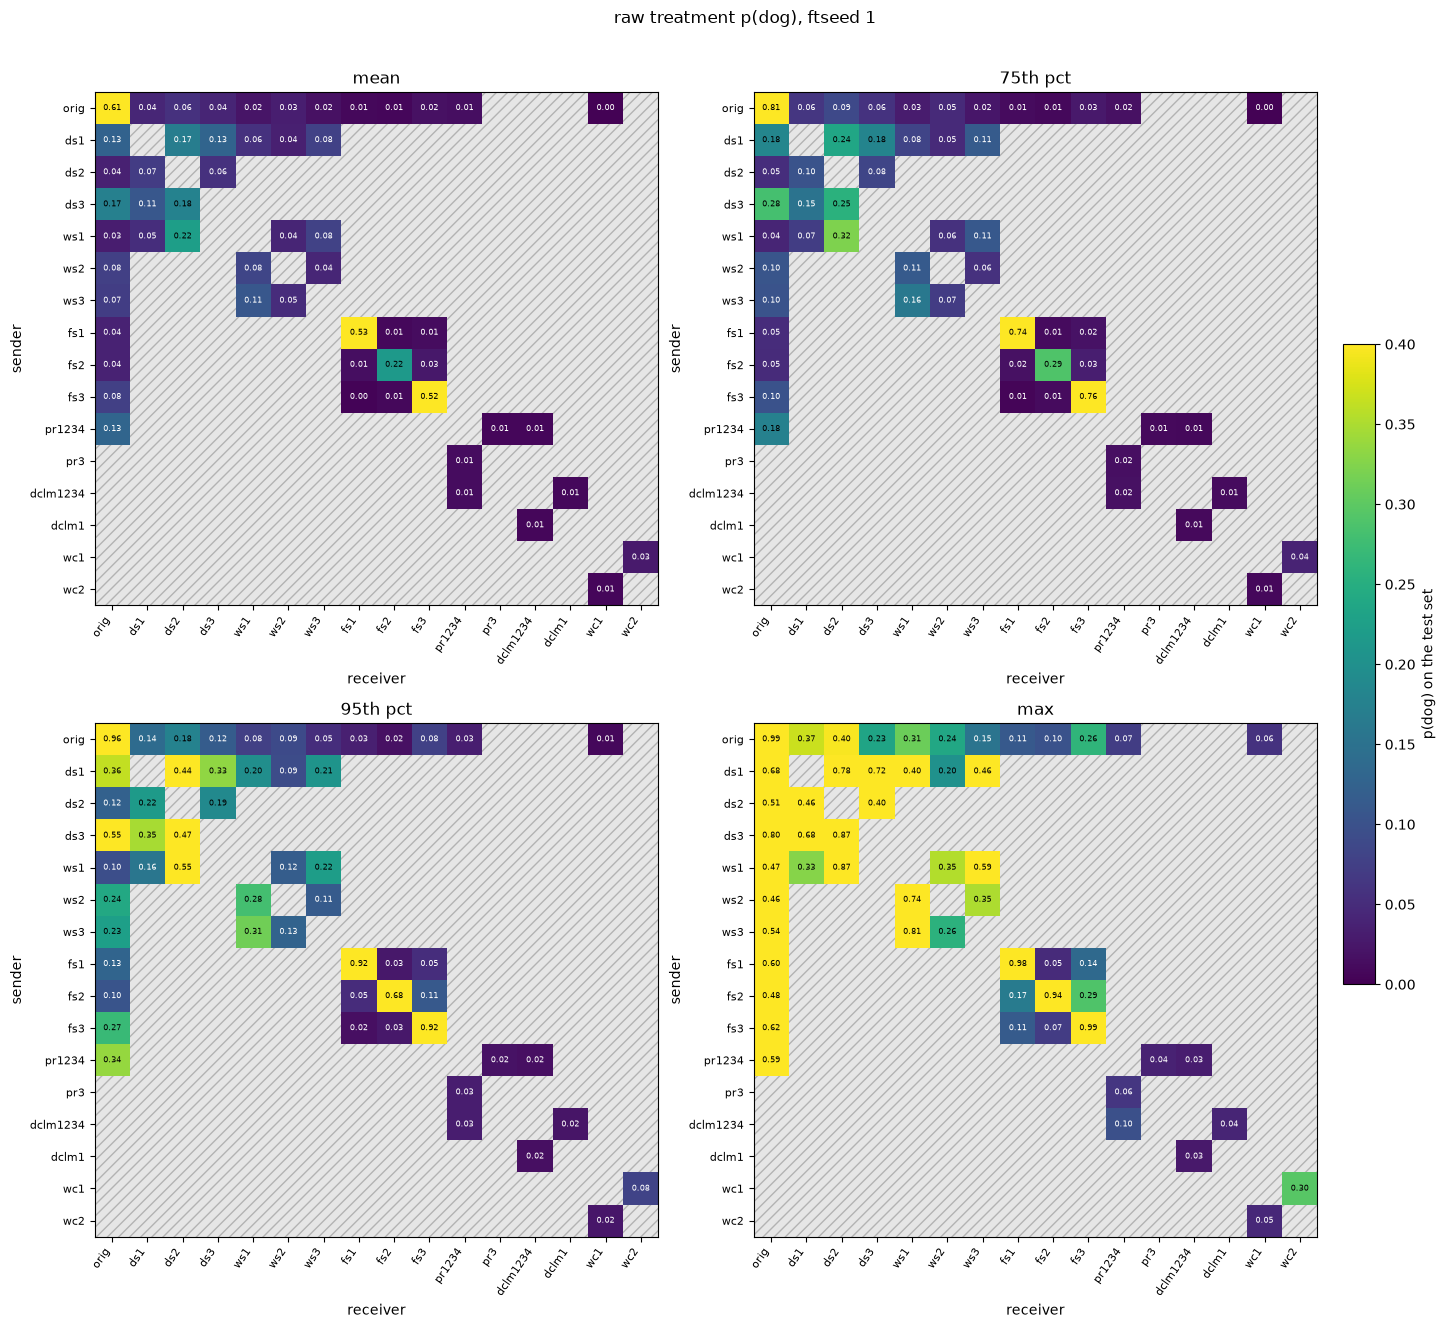

In [3]:
RAW = tm.transfer_matrices(RUNS, COV, value_col="treatment", cells30=C30)
FIG, _ = aplots.transfer_matrix_panels(RAW, vmin=0.0, vmax=0.4, title="raw treatment p(dog), ftseed 1",
                                       cbar_label="p(dog) on the test set")
FIG.savefig(REPO / "notebooks/figures/transfer_matrix_raw.png", dpi=150, bbox_inches="tight")

normalized vmax = 60.0


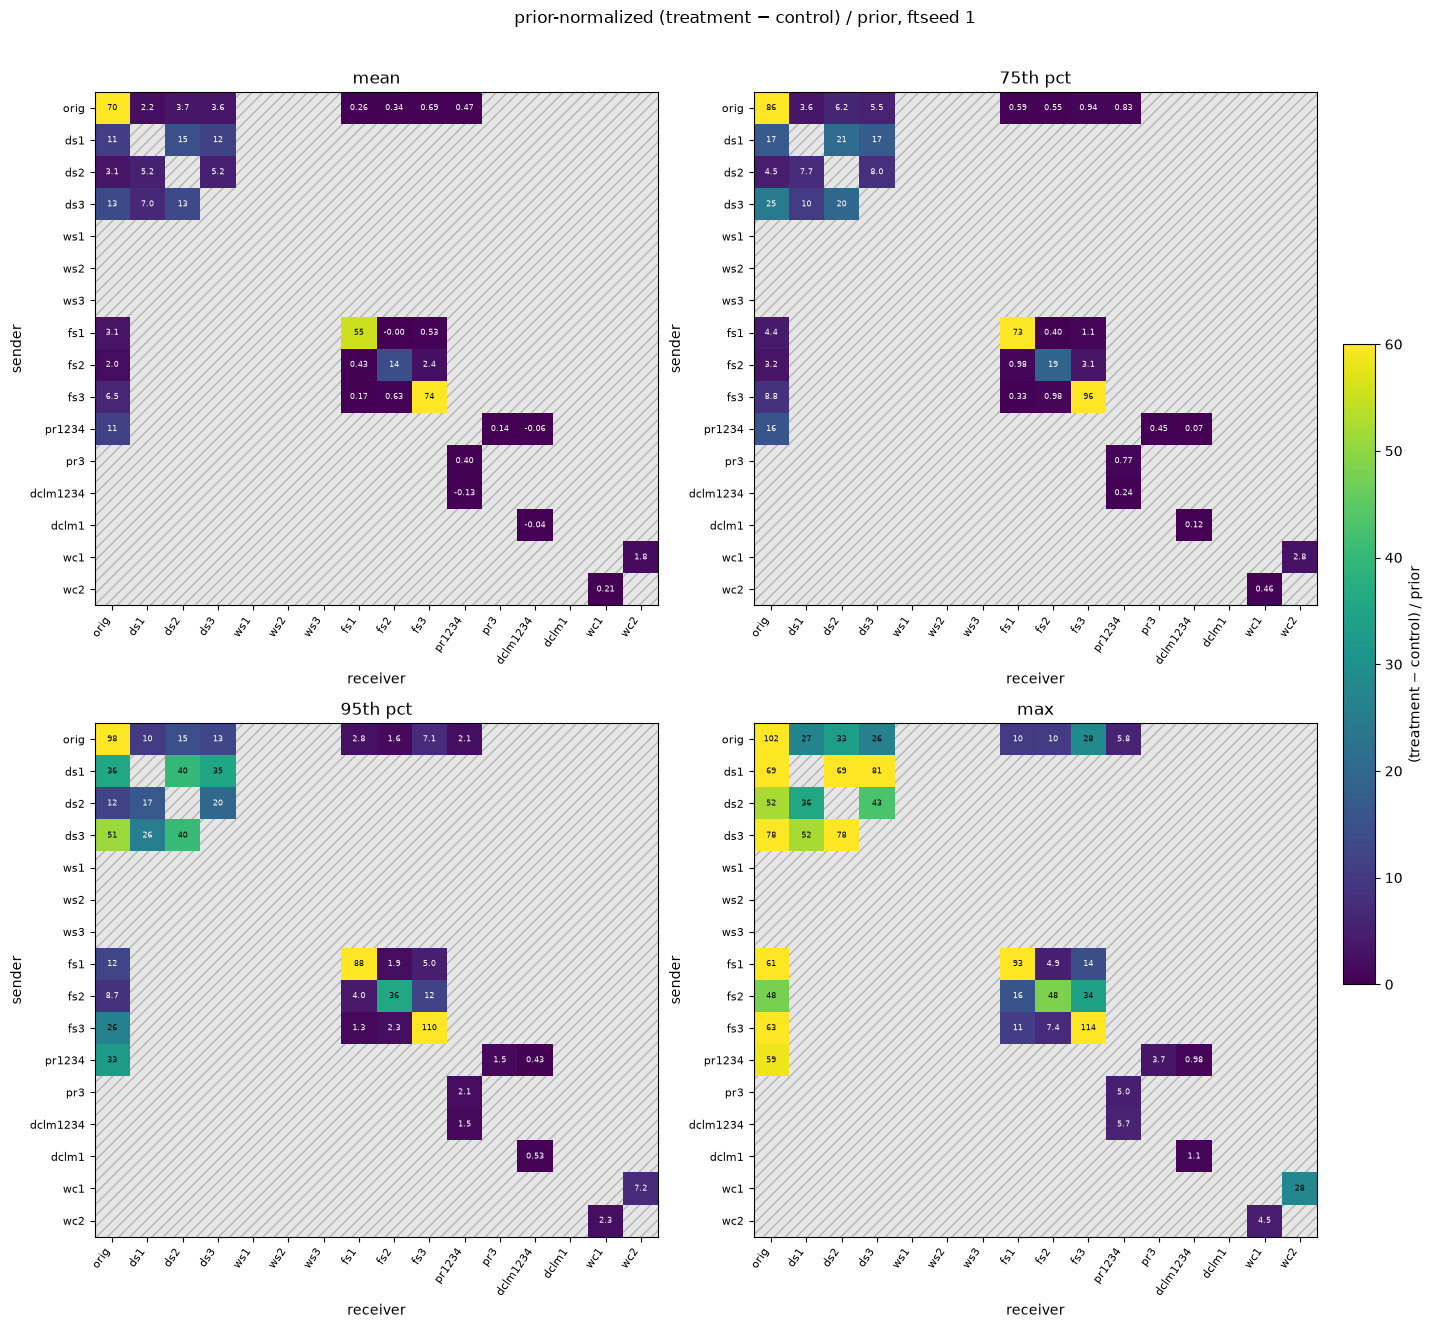

In [4]:
REL = tm.transfer_matrices(RUNS, COV, value_col="value_rel", cells30=C30)
VMAX = tm.default_vmax(REL)
print("normalized vmax =", VMAX)
FIG2, _ = aplots.transfer_matrix_panels(REL, vmin=0.0, vmax=VMAX, title="prior-normalized (treatment − control) / prior, ftseed 1",
                                        cbar_label="(treatment − control) / prior", fmt=tm.adaptive_fmt)
FIG2.savefig(REPO / "notebooks/figures/transfer_matrix_rel.png", dpi=150, bbox_inches="tight")

## Transfer by relationship of sender and receiver

Every ordered 160m arm is put in ONE relationship category from the `diagonal_direction.MODELS` facts (init class, data-order class, corpus, code tree), **both directions of a pair pooled into one row**:

1. **self (x→x)** — sender = receiver.
2. **same-model siblings** — different models, same init, same order, same corpus, same tree (orig↔ws1/2/3, ws↔ws).
3. **cross-data-order, same init** — same init, different order (orig↔ds, ds↔ds, ws↔ds).
4. **cross-init, same data order** — different init, same order, same corpus, same tree (dclm1234↔dclm1, wc1↔wc2, pr1234↔pr3). orig↔wc1 differs in init AND tree, so it is `other` (noted `cross-init +tree` in the arm table).
5. **same init, different corpus** — pr1234↔dclm1234 (the order differs too; the corpus is the coarser fact; a shared tree is required, so wc1↔dclm1 — seed-1 inits on *different* trees — is `other`).
6. **same init, different tree** — orig↔pr1234.
7. **cross-init + cross-data-order** — orig↔fs, fs↔fs, ds↔fs, ws↔fs.
8. **cross-width, same data order** — 160m↔410m.
9. **cross-width, different data order** — 160m↔410m-seed1.

Anything else (`other`: a pair differing in init and tree — orig↔wc1 — or in corpus and tree — wc1↔dclm1) is listed in the arm table only.

**Pooling.** Per arm, each order statistic (mean / 75th / 95th / max) over its runs; per category, the **median and the max over arms** of that per-arm statistic (`median X · max Y` on the cell's first line; the colour is the median), `n` = arms. The mean over arms stays available (`RelationshipSummary.grid_mean`) but is not plotted. The cell's second line is `n=k arms, m/N runs`: `m` runs present across the row's arms, `N = k × 300` (10 teachers × 30 core30 cells per arm).

**core30 rule (this view only).** Unlike the 16 × 16 heatmaps above, an arm is NOT dropped for partial coverage: every on-disk 160m arm with at least one core30 run enters, scored on whatever core30 runs it has, and carries `complete = k/300`. Arms with no core30 run are listed in the table only (`no core30 runs`). Raw = treatment p(dog); normalized = (treatment − control) / prior over the runs with a finite control (the normalized `m` counts those runs).

**Cross-width arms are on a different footing.** Rows 8–9 come from `run_logs/xarch/xarch_significance_arms.json` with *whatever teachers and cells exist* (160m→410m: 4 teachers; 410m→160m, 410m-seed1→160m, 160m→410m-seed1: 1 teacher each; a 410m-specific cell lattice, matched control per cell), not the 10 k-band teachers × core30. Their second line reads `n=k arms, m runs, t teachers`. Colour scales are per panel: raw 0–0.4, normalized 0–the `default_vmax` of the non-self rows (the self row saturates, its label is the true value).

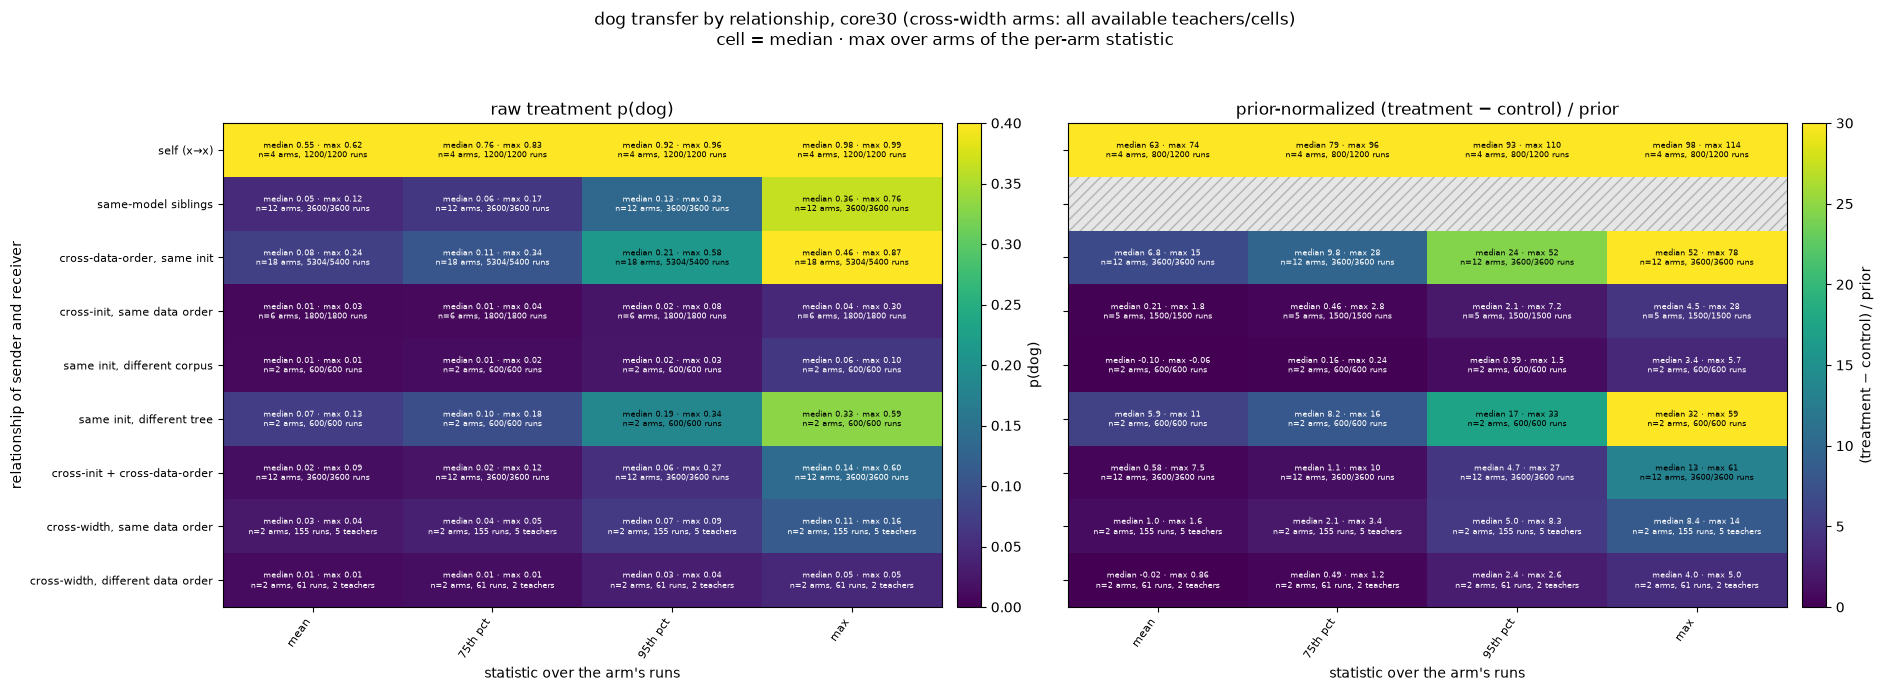

In [5]:
XARCH = tm.load_xarch_runs(REPO / "run_logs/xarch/xarch_significance_arms.json", output_root=OUT)
TAB = tm.relationship_arm_table(RUNS, COV, cells30=C30, on_disk=ARMS, xarch_runs=XARCH)
RAW_S, REL_S = tm.relationship_summary(TAB, "raw"), tm.relationship_summary(TAB, "rel")
FIG3, _ = aplots.relationship_panels(RAW_S.grid, REL_S.grid, raw_sub=RAW_S.sublabels(), rel_sub=REL_S.sublabels(),
                                     raw_labels=RAW_S.value_labels(), rel_labels=REL_S.value_labels(tm.adaptive_fmt),
                                     rel_vmax=tm.relationship_vmax(REL_S), rel_fmt=tm.adaptive_fmt,
                                     title="dog transfer by relationship, core30 (cross-width arms: all available teachers/cells)")
FIG3.savefig(REPO / "notebooks/figures/transfer_relationship.png", dpi=150, bbox_inches="tight")

In [6]:
pd.set_option("display.max_rows", 500)
tm.sort_arm_table(TAB).round(2)

,category,sender,receiver,arm,design,complete,n_teachers,n_cells,n_runs,n_runs_with_control,note,version,mean,p75,p95,max
0,self (x→x),ds1,ds1,ds1->ds1,None,0/300,0,0,0,0,no core30 runs,rel,NaN,NaN,NaN,NaN
1,self (x→x),ds1,ds1,ds1->ds1,None,0/300,0,0,0,0,no core30 runs,raw,NaN,NaN,NaN,NaN
2,self (x→x),fs1,fs1,fs1->fs1,core56,300/300,10,30,300,200,,rel,55.44,72.62,87.51,93.25
3,self (x→x),fs1,fs1,fs1->fs1,core56,300/300,10,30,300,200,,raw,0.55,0.75,0.92,0.98
4,self (x→x),fs2,fs2,fs2->fs2,core56,300/300,10,30,300,200,,rel,14.43,19.33,35.69,48.18
5,self (x→x),fs2,fs2,fs2->fs2,core56,300/300,10,30,300,200,,raw,0.19,0.27,0.55,0.88
6,self (x→x),fs3,fs3,fs3->fs3,core56,300/300,10,30,300,200,,rel,73.52,95.76,109.93,114.13
7,self (x→x),fs3,fs3,fs3->fs3,core56,300/300,10,30,300,200,,raw,0.56,0.78,0.93,0.97
8,self (x→x),orig,orig,orig->orig,core56,300/300,10,30,300,200,,rel,69.72,85.81,97.90,101.79
9,self (x→x),orig,orig,orig->orig,core56,300/300,10,30,300,200,,raw,0.62,0.83,0.96,0.99


## Significance: exceedance over the matched control, by relationship

**Statistic.** For an arm, the number of treatment runs (teacher × cell, ftseed 1) whose test p(dog) is *strictly above the maximum of that arm's control runs* (the untuned sender's numbers pool distilled into the receiver, same cells, same seed). **Null:** within each cell, which column is the control is arbitrary, so the control label is relabelled uniformly among that cell's finite runs, independently across cells — each cell's set of values stays fixed, only the treatment/control assignment moves (`stats.transfer_significance_tests.stratified_exceedance_permutation`, 20 000 draws, seed 0; p floor 5e-5). Only cells with a finite control take part; the **exceedance fraction** shown is exceedances / testable treatment runs.

**Per arm vs pooled.** Per arm: one matrix (its core30 cells × [10 teachers, control]; cross-width arms: their own teachers × cells), one p. Per category: every testable arm's matrix stacked with `groups` = arm, so each arm's exceedances are counted against its **own** control maximum and summed — a single global control maximum across arms would let the loudest receiver's control silently become every arm's threshold. `arms p<0.05` counts arms whose *per-arm* p clears 0.05.

**Untestable ≠ null.** An arm with no matched control at all (every ws endpoint, orig→wc1, dclm1234→dclm1) cannot be tested and is NaN / hatched, not "not significant". The same-model-siblings row is entirely untestable.

**Arm counts overstate independence.** Arms share senders (the same ten teachers feed every arm of a sender) and receivers, so `k / n arms` is a tally, not k independent replications.

,category,n_arms_testable,n_arms_total,n_runs,n_exceed,exceed_frac,perm_p,n_arms_sig
0,self (x→x),4,4,800,791,0.99,5.00e-05,4
1,same-model siblings,0,12,0,NaN,NaN,NaN,0
2,"cross-data-order, same init",12,18,3600,2175,0.60,5.00e-05,12
3,"cross-init, same data order",5,6,1500,259,0.17,5.00e-05,3
4,"same init, different corpus",2,2,600,40,0.07,8.88e-02,0
5,"same init, different tree",2,2,600,312,0.52,5.00e-05,2
6,cross-init + cross-data-order,12,12,3600,782,0.22,5.00e-05,7
7,"cross-width, same data order",2,2,155,34,0.22,1.00e-04,2
8,"cross-width, different data order",2,2,61,15,0.25,2.00e-04,1


,category,arm,n_testable_runs,n_exceed,exceed_frac,perm_p,floor
0,self (x→x),fs1->fs1,200,199,0.99,5.00e-05,5.0e-05
1,self (x→x),fs2->fs2,200,196,0.98,5.00e-05,5.0e-05
2,self (x→x),fs3->fs3,200,196,0.98,5.00e-05,5.0e-05
3,self (x→x),orig->orig,200,200,1.00,5.00e-05,5.0e-05
4,same-model siblings,orig->ws1,0,NaN,NaN,NaN,5.0e-05
5,same-model siblings,orig->ws2,0,NaN,NaN,NaN,5.0e-05
6,same-model siblings,orig->ws3,0,NaN,NaN,NaN,5.0e-05
7,same-model siblings,ws1->orig,0,NaN,NaN,NaN,5.0e-05
8,same-model siblings,ws1->ws2,0,NaN,NaN,NaN,5.0e-05
9,same-model siblings,ws1->ws3,0,NaN,NaN,NaN,5.0e-05


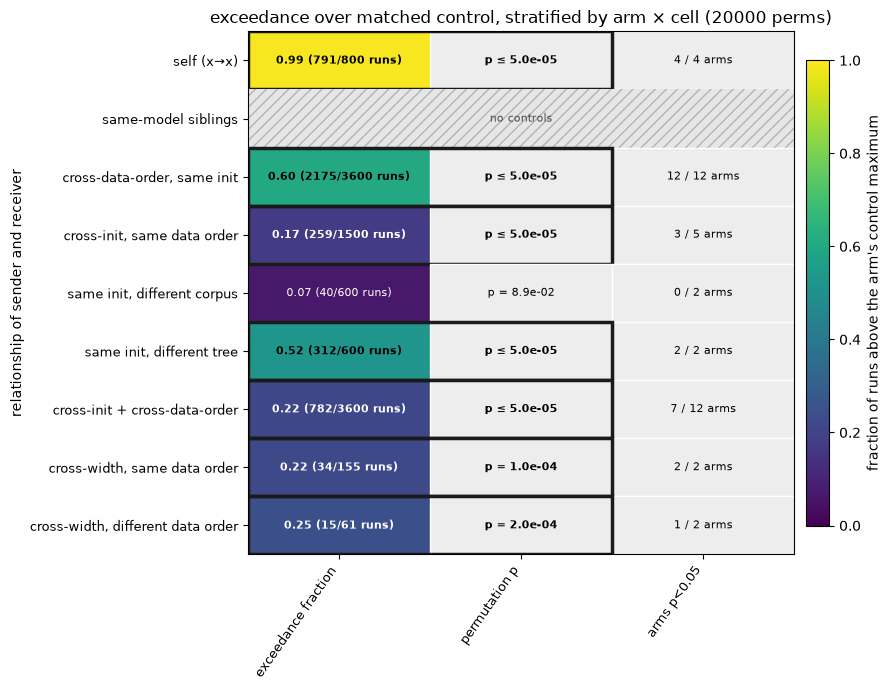

In [7]:
from IPython.display import display
PER_ARM, POOLED = tm.relationship_exceedance_table(RUNS, cells30=C30, on_disk=ARMS, xarch_runs=XARCH, n_perm=20000, seed=0)
FIG4, _ = aplots.relationship_significance_panel(POOLED, n_perm=20000)
FIG4.savefig(REPO / "notebooks/figures/transfer_relationship_significance.png", dpi=150, bbox_inches="tight")
display(tm.style_exceedance_table(POOLED))
tm.style_exceedance_table(PER_ARM)